# 02 — RGB and Grayscale

An RGB image stores three measurements per pixel; grayscale reduces these to one. This reduction changes the information available to later vision algorithms.

## Learning objectives
- Inspect channel order, shape, dtype, and intensity range.
- Derive and implement weighted grayscale conversion with NumPy.
- Distinguish gamma-encoded luma from linear-light luminance.
- Explain differences between OpenCV and scikit-image outputs.

Run all cells in order. Only the bundled `skimage.data.astronaut()` image is used; no external files or downloads are required.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
np.set_printoptions(precision=4, suppress=True)

## 1. Mathematical foundations

For an RGB array $I\in\{0,\ldots,255\}^{H\times W\times3}$, each pixel is $(R,G,B)$. Normalize to $[0,1]$ before floating-point arithmetic. A simple average treats channels equally, whereas a common luma approximation uses

$$Y'=0.299R'+0.587G'+0.114B'.$$

Primes denote nonlinear, gamma-encoded signals. The larger green coefficient reflects visual sensitivity. These coefficients sum to one, so neutral pixels remain neutral. This is a luma-style approximation, not a complete color-management pipeline.

Physical relative luminance instead uses **linear-light** sRGB channels:

$$C_{lin}=\begin{cases}C'/12.92&C'\leq0.04045\\((C'+0.055)/1.055)^{2.4}&C'>0.04045,\end{cases}$$
$$Y=0.2126R_{lin}+0.7152G_{lin}+0.0722B_{lin}.$$

Averaging encoded values and averaging light are different operations. Floating-point conversion also prevents overflow in expressions such as $R+G+B$.

Shape: (512, 512, 3) | dtype: uint8 | range: (np.uint8(0), np.uint8(255))
Array storage: 786432 bytes; float64 storage: 6291456 bytes


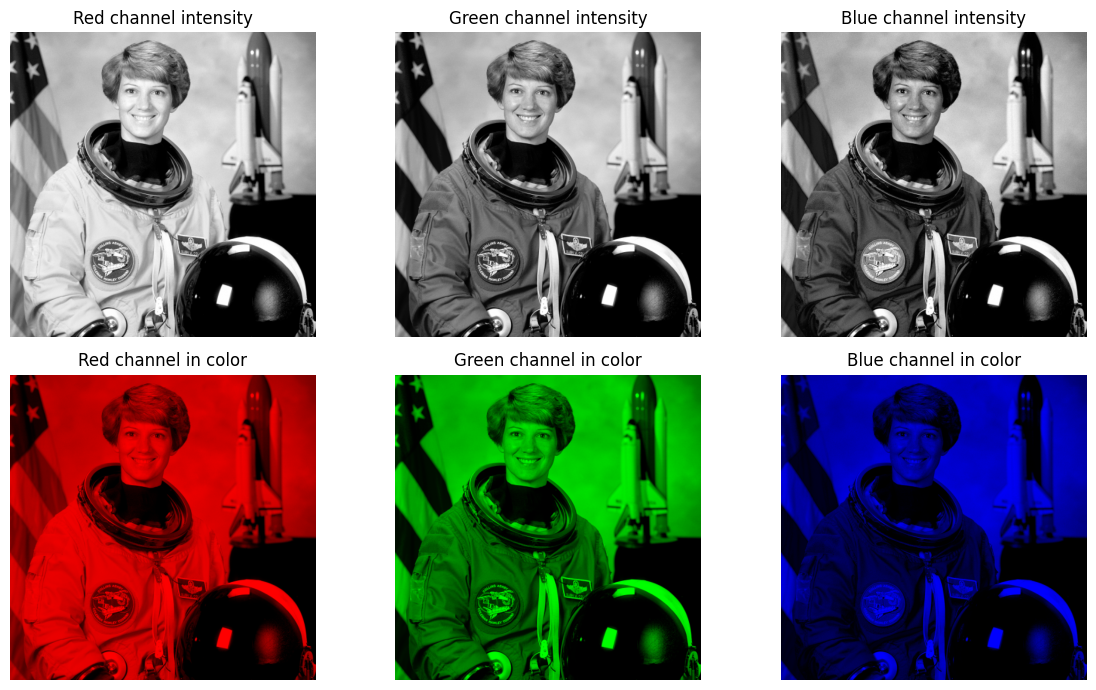

In [2]:
rgb = data.astronaut()
assert rgb.dtype == np.uint8 and rgb.ndim == 3 and rgb.shape[2] == 3
rgb_float = rgb.astype(np.float64) / 255.0
print('Shape:', rgb.shape, '| dtype:', rgb.dtype, '| range:', (rgb.min(), rgb.max()))
print('Array storage:', rgb.nbytes, 'bytes; float64 storage:', rgb_float.nbytes, 'bytes')

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for channel, name in enumerate(['Red', 'Green', 'Blue']):
    axes[0, channel].imshow(rgb[..., channel], cmap='gray', vmin=0, vmax=255)
    axes[0, channel].set_title(name + ' channel intensity')
    isolated = np.zeros_like(rgb)
    isolated[..., channel] = rgb[..., channel]
    axes[1, channel].imshow(isolated)
    axes[1, channel].set_title(name + ' channel in color')
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

The first row uses a shared grayscale scale to compare channel measurements. The second row shows their RGB contributions. Brightness differences are scene-dependent: a bright red object need not remain bright in grayscale.

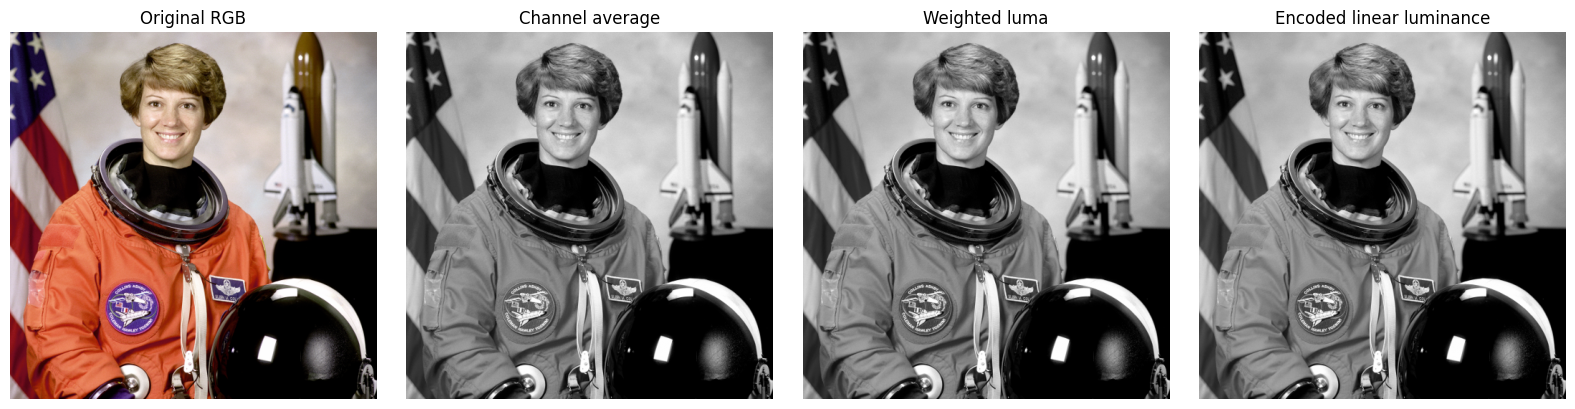

In [3]:
weights = np.array([0.299, 0.587, 0.114])
luma = rgb_float @ weights
average = rgb_float.mean(axis=2)
linear_rgb = np.where(rgb_float <= 0.04045, rgb_float / 12.92,
                      ((rgb_float + 0.055) / 1.055) ** 2.4)
luminance = linear_rgb @ np.array([0.2126, 0.7152, 0.0722])
# Encode the linear luminance for a display-oriented grayscale comparison.
luminance_encoded = np.where(luminance <= 0.0031308, 12.92 * luminance,
                             1.055 * luminance ** (1 / 2.4) - 0.055)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, arr, title in zip(axes, [rgb, average, luma, luminance_encoded],
                         ['Original RGB', 'Channel average', 'Weighted luma', 'Encoded linear luminance']):
    ax.imshow(arr, cmap='gray', vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()
assert luma.shape == rgb.shape[:2] and 0 <= luma.min() <= luma.max() <= 1
assert np.allclose(np.ones((1, 1, 3)) @ weights, 1)

## 2. Library comparison and channel order

OpenCV conventionally receives BGR images from its image loader, but our sample is RGB. Use `COLOR_RGB2GRAY` explicitly. Integer implementations can differ by one intensity unit because of coefficient precision and rounding.

`skimage.color.rgb2gray` returns a float array in $[0,1]$ for this uint8 input and uses coefficients approximately $(0.2125,0.7154,0.0721)$ on the supplied encoded channels. It does **not** perform the sRGB linearization above. Therefore its result need not match OpenCV, and should not be equated with our linear-light luminance.

OpenCV max absolute uint8 difference: 1
OpenCV mean absolute uint8 difference: 0.000690460205078125
scikit-image coefficient check: 2.220446049250313e-16


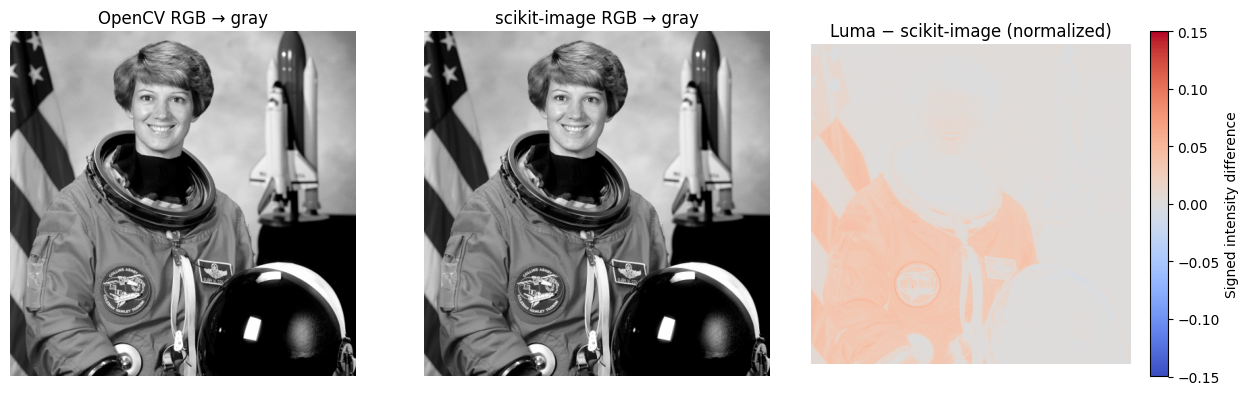

In [4]:
from skimage.color import rgb2gray

manual_u8 = np.clip(np.rint(255 * luma), 0, 255).astype(np.uint8)
cv_gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
sk_gray = rgb2gray(rgb)
sk_manual = rgb_float @ np.array([0.2125, 0.7154, 0.0721])
error = manual_u8.astype(np.int16) - cv_gray.astype(np.int16)
print('OpenCV max absolute uint8 difference:', np.abs(error).max())
print('OpenCV mean absolute uint8 difference:', np.abs(error).mean())
print('scikit-image coefficient check:', np.max(np.abs(sk_gray - sk_manual)))
assert np.abs(error).max() <= 1
assert np.allclose(sk_gray, sk_manual)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(cv_gray, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('OpenCV RGB → gray')
axes[1].imshow(sk_gray, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('scikit-image RGB → gray')
im = axes[2].imshow(luma - sk_gray, cmap='coolwarm', vmin=-0.15, vmax=0.15)
axes[2].set_title('Luma − scikit-image (normalized)')
fig.colorbar(im, ax=axes[2], label='Signed intensity difference')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. A controlled color experiment

Equal grayscale values do not imply equal colors. Pure primaries isolate the role of the weights; a deliberate RGB/BGR mistake provides a recognizable failure case.

Red, green, blue, neutral luma: [ 76 150  29 128]
Mean absolute error from wrong channel order: 8.862903594970703


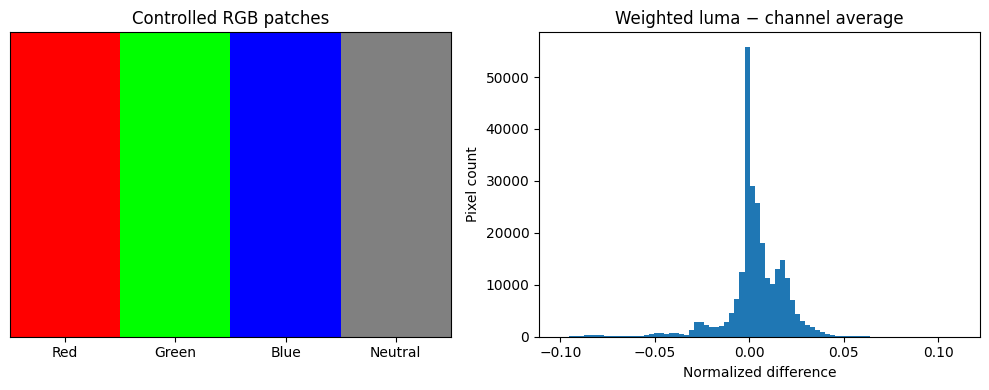

In [5]:
colors = np.array([[[255, 0, 0], [0, 255, 0], [0, 0, 255], [128, 128, 128]]], dtype=np.uint8)
print('Red, green, blue, neutral luma:', cv2.cvtColor(colors, cv2.COLOR_RGB2GRAY).ravel())
wrong_gray = cv2.cvtColor(rgb, cv2.COLOR_BGR2GRAY)
print('Mean absolute error from wrong channel order:',
      np.mean(np.abs(wrong_gray.astype(float) - cv_gray.astype(float))))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(colors, aspect='auto')
axes[0].set_xticks(range(4), ['Red', 'Green', 'Blue', 'Neutral'])
axes[0].set_yticks([])
axes[0].set_title('Controlled RGB patches')
axes[1].hist((luma - average).ravel(), bins=80)
axes[1].set(title='Weighted luma − channel average', xlabel='Normalized difference', ylabel='Pixel count')
plt.tight_layout()
plt.show()

## Interpretation, limitations, and review

The coefficient checks separate implementation error from a deliberate change in the model. Inspect the signed difference image to see which colored regions are most affected. A common grayscale display range makes visual comparisons meaningful.

Grayscale discards chromatic distinctions irreversibly: many RGB triples map to the same scalar. Camera response, white balance, and color space affect the meaning of the channels. A display image is not a calibrated measurement of scene radiance.

1. Why do all three weighted methods preserve neutral pixels?
2. Construct two different RGB colors with nearly equal OpenCV grayscale values.
3. Why is subtracting uint8 arrays directly unsafe for an error image?
4. What changes when averaging is performed before versus after sRGB linearization?

## Summary and connection

Grayscale is a projection from three channels to one. This reduces memory and computation for classical Computer Vision, but removes color cues that a CNN could learn to use. Signal Processing distinguishes operations on encoded signals from operations on linear-light measurements; the distinction matters before filtering or measuring brightness.